# MEMC exercise 9 – The insurance company, complete

---

In **exercise 2** we built the insurance company and arrived at a first estimate of the probability of
ruin. But that is where we got stuck: a crude band of $\pm 2$ standard errors is not enough for rare
events, and we never got to the question "how much capital do we need" at all.

Now we have the tools from exercises 3 to 7 and we can finish the problem.

| What we use | Where from |
|---|---|
| $R = \sqrt{\gamma}$, geometric gaps | the inverse transform, exercises 3 and 4 |
| the claim times during the year | ordered samples, exercise 5 |
| confidence intervals (CLT, Chebyshev, Wilson) | exercises 0 and 2 |
| rare ruins without billions of runs | importance sampling, exercise 7 |

At the end we will be able to answer the question an insurance company actually cares about: **what
capital is enough to keep the probability of ruin below one in a thousand?**

In [1]:
import math
import random
import time
from bisect import bisect_right

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(sampler, n):
    '''Plain Monte Carlo: the average of n calls of the generator and its standard error sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {spaces(mean, ',.5g')} +- {spaces(se, ',.2g')}  (exact {spaces(exact, ',.5g')})")
    assert abs(mean - exact) <= k * se, name


def Phi(x):
    '''Distribution function of N(0, 1).'''
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


def spaces(x, spec=","):
    '''A number with spaces instead of commas as the thousands separator.'''
    return format(x, spec).replace(",", " ")

## 1. The model and the generators

A reminder of the model from exercise 2: the year has $N$ intervals, in each one a claim occurs
independently with probability $p$, and its size is $X = L\cdot R$ with the density of $R$ equal to
$2r$ on $[0,1]$. The capital is $K$, and ruin happens exactly when the annual payout $T$ exceeds $K$.

Two generators we can now derive:

**The claim size** (the inverse transform, exercise 4). From $F(r) = r^2$ we get
$F^{-1}(\gamma) = \sqrt{\gamma}$, so $R = \sqrt{\gamma}$.

**The gap between claims** (the geometric distribution, exercise 3). The number of empty intervals
before the next claim is geometric and we can produce it with a single number:

$$G = \left\lfloor \frac{\ln \gamma}{\ln(1-p)} \right\rfloor .$$

So instead of $N$ draws we make only as many as there are claims.

In [2]:
SCENARIO_A = dict(N=365, p=0.05, L=10_000, K=200_000)
SCENARIO_B = dict(N=1000, p=0.15, L=100_000, K=10_000_000)


def claim(L):
    '''The size of one claim: L * R, where R has density 2r on [0, 1] (exercise 4: R = sqrt(γ)).'''
    return L * math.sqrt(random.random())


def annual_payout_slow(N, p, L):
    '''The literal simulation: we walk through all N intervals.'''
    T = 0.0
    for _ in range(N):
        if random.random() < p:
            T += claim(L)
    return T


def annual_payout(N, p, L):
    '''The annual payout T: we jump by geometric gaps (exercise 3).'''
    lq = math.log(1.0 - p)
    T = 0.0
    pos = -1
    while True:
        pos += 1 + int(math.log(1.0 - random.random()) / lq)   # 1 - γ is uniform too, and never 0
        if pos >= N:
            return T
        T += claim(L)


def theory(N, p, L, K):
    '''The exact E T, D T and the CLT approximation of p_u.'''
    mu = 2 * L / 3
    EX2 = L * L / 2
    ET = N * p * mu
    VarT = N * (p * EX2 - (p * mu) ** 2)
    return ET, VarT, 1 - Phi((K - ET) / math.sqrt(VarT))


sc = SCENARIO_A
ET, VarT, p_clt = theory(**sc)

n = 100_000
t0 = time.perf_counter()
m, se = estimate(lambda: annual_payout_slow(sc["N"], sc["p"], sc["L"]), 20_000)
t_slow = (time.perf_counter() - t0) / 20_000
check("E T (literal)", m, se, ET)

t0 = time.perf_counter()
m, se = estimate(lambda: annual_payout(sc["N"], sc["p"], sc["L"]), n)
t_fast = (time.perf_counter() - t0) / n
check("E T (geometric gaps)", m, se, ET)
print(f"speed-up: {t_slow / t_fast:.0f}x  ({t_slow * 1e6:.0f} → {t_fast * 1e6:.1f} microseconds per year)")

E T (literal): 1.2177e+05 +- 2.1e+02  (exact 1.2167e+05)


E T (geometric gaps): 1.2161e+05 +- 93  (exact 1.2167e+05)
speed-up: 4x  (13 → 3.6 microseconds per year)


## 2. The course of the year: the claim times

For $p_u$ itself the total payout $T$ is all we need. But when we want to see the **course** of the
year, we need the claim times — and those come from exercise 5: $k$ sorted uniform numbers can be
produced in $O(k)$ time without sorting, by the top-down recurrence

$$\gamma_{(k)} = \gamma_{(k+1)}\cdot V^{1/k}, \qquad \gamma_{(n)} = V^{1/n}.$$

The number of claims in the year is $\operatorname{Binomial}(N, p)$, and their times are then uniform
and independent — i.e. exactly a sorted uniform sample rescaled to the length of the year.

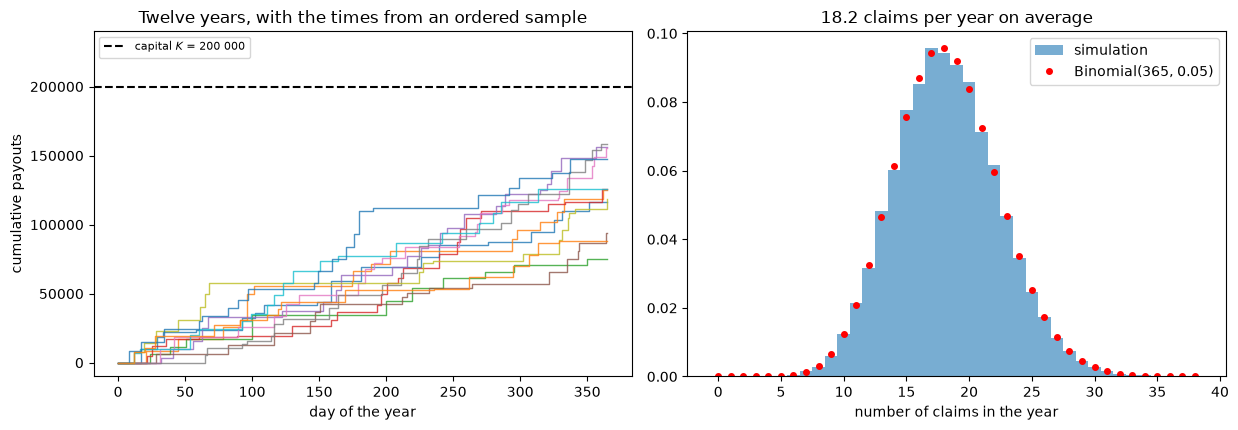

In [3]:
def ordered_uniforms(n):
    '''n sorted uniform numbers on (0, 1) in O(n) time (exercise 5).'''
    out = [0.0] * n
    u = 1.0
    for k in range(n, 0, -1):
        u *= random.random() ** (1.0 / k)
        out[k - 1] = u
    return out


def binomial(N, p):
    '''The number of successes out of N trials, via geometric gaps (exercise 3).'''
    lq = math.log(1.0 - p)
    pos, k = -1, 0
    while True:
        pos += 1 + int(math.log(1.0 - random.random()) / lq)
        if pos >= N:
            return k
        k += 1


def year_path(N, p, L):
    '''One year as (times, cumulative payouts).'''
    k = binomial(N, p)
    times = [t * N for t in ordered_uniforms(k)]
    cum, s = [], 0.0
    for _ in times:
        s += claim(L)
        cum.append(s)
    return times, cum


sc = SCENARIO_A
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
for _ in range(12):
    times, cum = year_path(sc["N"], sc["p"], sc["L"])
    ax.step([0] + times + [sc["N"]], [0.0] + cum + [cum[-1] if cum else 0.0],
            where="post", lw=1, alpha=0.8)
ax.axhline(sc["K"], color="k", ls="--", label=f"capital $K$ = {spaces(sc['K'])}")
ax.set_xlabel("day of the year")
ax.set_ylabel("cumulative payouts")
ax.set_ylim(top=sc["K"] * 1.2)
ax.set_title("Twelve years, with the times from an ordered sample")
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
counts = [binomial(sc["N"], sc["p"]) for _ in range(50_000)]
kmax = max(counts) + 1
ax.hist(counts, bins=[k - 0.5 for k in range(kmax + 1)], density=True, alpha=0.6, label="simulation")
lam = sc["N"] * sc["p"]
ax.plot(range(kmax), [math.comb(sc["N"], k) * sc["p"] ** k * (1 - sc["p"]) ** (sc["N"] - k) for k in range(kmax)],
        "ro", ms=4, label=f"Binomial({sc['N']}, {sc['p']})")
ax.set_xlabel("number of claims in the year")
ax.set_title(f"{lam:.1f} claims per year on average")
ax.legend()
plt.tight_layout()
plt.show()

## 3. A confidence interval for $p_u$

The estimate $\hat p = \bar X_M$ from $M$ runs is an average of Bernoulli variables. We can compute an
interval around it in four ways (confidence $1-\alpha = 95\,\%$,
$\hat\sigma = \sqrt{\hat p(1-\hat p)}$):

| Method | Interval | Note |
|--------|----------|------|
| CLT | $\hat p \pm 1.96\,\hat\sigma/\sqrt{M}$ | the most used one, good for a larger $M\hat p$ |
| Chebyshev | $\hat p \pm \hat\sigma/\sqrt{M\alpha}$ | always holds (with the exact $\sigma$), 2.3x wider |
| Chebyshev, $\sigma = 1/2$ | $\hat p \pm 1/(2\sqrt{M\alpha})$ | truly guaranteed, but crude |
| Wilson | an adjusted centre and width | works even for a $\hat p$ close to zero |

The Wilson interval is

$$\frac{\hat p + \frac{z^2}{2M}}{1 + \frac{z^2}{M}} \;\pm\; \frac{z}{1 + \frac{z^2}{M}}\sqrt{\frac{\hat p(1-\hat p)}{M} + \frac{z^2}{4M^2}}, \qquad z = 1.96.$$

Why Wilson in particular: the CLT and the Chebyshev intervals both rest on $\hat\sigma$, and when
$\hat p = 0$ we have $\hat\sigma = 0$ and the interval collapses to the single point $[0,0]$ — i.e. to
the claim "ruin is impossible". Wilson's width is derived differently and avoids this trap.

In [4]:
def ruin_fraction(sc, M):
    '''The fraction of M simulated years in which the payouts exceeded K.'''
    N, p, L, K = sc["N"], sc["p"], sc["L"], sc["K"]
    return sum(annual_payout(N, p, L) > K for _ in range(M)) / M


def _bounds(center, half):
    return max(0.0, center - half), min(1.0, center + half)


def interval_clt(p_hat, M, z=1.96):
    return _bounds(p_hat, z * math.sqrt(p_hat * (1 - p_hat) / M))


def interval_cheb(p_hat, M, alpha=0.05):
    return _bounds(p_hat, math.sqrt(p_hat * (1 - p_hat) / (M * alpha)))


def interval_cheb_worst(p_hat, M, alpha=0.05):
    return _bounds(p_hat, 0.5 / math.sqrt(M * alpha))


def interval_wilson(p_hat, M, z=1.96):
    d = 1 + z * z / M
    center = (p_hat + z * z / (2 * M)) / d
    half = z / d * math.sqrt(p_hat * (1 - p_hat) / M + z * z / (4 * M * M))
    return _bounds(center, half)


M_ = 20_000
p_hat = ruin_fraction(SCENARIO_B, M_)
print(f"scenario B (ruin in half the years), M = {spaces(M_)}: p_u = {p_hat:.4f}   (CLT: {theory(**SCENARIO_B)[2]:.4f})")
for name, f in (("CLT", interval_clt), ("Chebyshev", interval_cheb), ("Wilson", interval_wilson)):
    lo, hi = f(p_hat, M_)
    print(f"  {name:10s} [{lo:.4f}, {hi:.4f}]   width {hi - lo:.4f}")

print("\nscenario A (rare ruin), with increasing M:")
print(f"{'M':>8s} {'p est.':>9s}   {'CLT interval':>22s}   {'Wilson interval':>22s}")
for M_ in (10, 30, 100, 1_000, 10_000, 100_000):
    p_hat = ruin_fraction(SCENARIO_A, M_)
    lo1, hi1 = interval_clt(p_hat, M_)
    lo2, hi2 = interval_wilson(p_hat, M_)
    print(f"{spaces(M_, '8,d')} {p_hat:9.5f}   [{lo1:.5f}, {hi1:.5f}]   [{lo2:.5f}, {hi2:.5f}]")

scenario B (ruin in half the years), M = 20 000: p_u = 0.5004   (CLT: 0.5000)
  CLT        [0.4935, 0.5074]   width 0.0139
  Chebyshev  [0.4846, 0.5163]   width 0.0316
  Wilson     [0.4935, 0.5074]   width 0.0139

scenario A (rare ruin), with increasing M:
       M    p est.             CLT interval          Wilson interval
      10   0.00000   [0.00000, 0.00000]   [0.00000, 0.27754]
      30   0.00000   [0.00000, 0.00000]   [0.00000, 0.11352]
     100   0.00000   [0.00000, 0.00000]   [0.00000, 0.03699]
   1 000   0.00700   [0.00183, 0.01217]   [0.00339, 0.01438]
  10 000   0.00510   [0.00370, 0.00650]   [0.00388, 0.00670]


 100 000   0.00729   [0.00676, 0.00782]   [0.00678, 0.00784]


In scenario B, where $p_u \approx 0.5$, the CLT and Wilson agree for all practical purposes and
Chebyshev is roughly 2.3x wider (the ratio $4.47/1.96$).

In scenario A the trap is visible: for a small $M$ not a single ruin occurs, $\hat p = 0$, and the CLT
interval is the point $[0,0]$. Wilson is correctly wide and non-zero.

### Coverage: do the intervals deliver what they promise?

The phrase "a 95 % interval" means that over many repetitions it covers the truth in 95 % of cases.
Let us check that: we take the estimate from a large number of runs as the truth, and then repeat the
estimate from a small $M$ many times.

In [5]:
M_ref = 500_000
p_true = ruin_fraction(SCENARIO_A, M_ref)
print(f"reference value p_u = {p_true:.5f}  (from {spaces(M_ref)} runs)\n")

methods = (
    ("CLT", interval_clt),
    ("Chebyshev (est. sigma)", interval_cheb),
    ("Chebyshev (sigma = 1/2)", interval_cheb_worst),
    ("Wilson", interval_wilson),
)


def coverage_table(M_, runs):
    ok = {name: 0 for name, _ in methods}
    widths = {name: 0.0 for name, _ in methods}
    zeros = 0
    for _ in range(runs):
        p_hat = ruin_fraction(SCENARIO_A, M_)
        zeros += p_hat == 0
        for name, f in methods:
            lo, hi = f(p_hat, M_)
            ok[name] += lo <= p_true <= hi
            widths[name] += hi - lo
    print(f"M = {M_}, {runs} repetitions; runs without a single ruin: {zeros / runs:.1%}")
    print(f"  {'method':24s} {'coverage':>9s} {'average width':>16s}")
    for name, _ in methods:
        print(f"  {name:24s} {ok[name] / runs:9.1%} {widths[name] / runs:16.4f}")
    print()


coverage_table(100, 1000)
coverage_table(1000, 400)

reference value p_u = 0.00717  (from 500 000 runs)



M = 100, 1000 repetitions; runs without a single ruin: 51.2%
  method                    coverage    average width
  CLT                          48.7%           0.0178
  Chebyshev (est. sigma)       48.8%           0.0318
  Chebyshev (sigma = 1/2)     100.0%           0.2304
  Wilson                       96.6%           0.0468



M = 1000, 400 repetitions; runs without a single ruin: 0.0%
  method                    coverage    average width
  CLT                          94.8%           0.0102
  Chebyshev (est. sigma)      100.0%           0.0187
  Chebyshev (sigma = 1/2)     100.0%           0.0777
  Wilson                       98.0%           0.0109



The conclusions (the numbers shift slightly with the seed, the conclusions do not):

- **$M = 100$:** in roughly half the repetitions not a single ruin occurs, so the CLT interval and
  Chebyshev with an estimated $\sigma$ are both the point $[0,0]$. The coverage is around **50 %**,
  not the promised 95 %. Wilson holds above 95 %, even if it is wider.
- **$M = 1000$:** the zero runs are gone, the CLT is back near its promised 95 %, and Wilson is
  slightly conservative at 98 %.
- **Chebyshev with $\sigma = 1/2$** always covers, but its width (around $0.23$ at $M = 100$) is many
  times the value $p_u \approx 0.007$ itself. A guarantee that tells you nothing.

**The rule:** for rare events you need enough runs that the expected number of ruins $M p_u$ is at
least in the hundreds. For $p_u \approx 0.007$ that means $M \sim 10^5$. And if $p_u$ were
$\sim 10^{-6}$, we would need $10^8$ runs — which is already unbearable.

This is exactly where it pays to change the method.

## 4. Rare ruins: importance sampling

The problem plain Monte Carlo has with a rare event is simple: almost every run contributes zero. From
exercise 7 we know what to do about it — **generate from a different distribution and weight**.

Here a nice choice suggests itself. Ruin happens when the year has unusually **many** claims. So let
us draw the year with a larger claim probability $q > p$ and fix the error with a weight. The number
of claims $k$ has probability $\binom{N}{k}p^k(1-p)^{N-k}$ under $p$ and likewise under $q$, so

$$w(k) \;=\; \frac{P_p(k)}{P_q(k)} \;=\; \left(\frac{p}{q}\right)^{k}\left(\frac{1-p}{1-q}\right)^{N-k}.$$

We do not change the claim sizes; they cancel in the fraction. The estimate is

$$\hat p_u = \frac{1}{M}\sum_{i=1}^{M} w(k_i)\,\mathbf 1[T_i > K], \qquad k_i,\,T_i \text{ drawn with } q .$$

It is **unbiased** for any $q \in (0,1)$ — $q$ affects only the variance.

How to choose $q$? So that the event becomes typical: we want $E_q\,T = K$, and since
$E_q T = N q \cdot \tfrac{2L}{3}$, this gives

$$q^\star = \frac{K}{N\cdot 2L/3}.$$

We compute the weights **logarithmically**, otherwise they underflow.

In [6]:
def year_with_count(N, prob, L):
    '''One year drawn with probability prob; returns (payout T, number of claims k).'''
    lq = math.log(1.0 - prob)
    T, pos, k = 0.0, -1, 0
    while True:
        pos += 1 + int(math.log(1.0 - random.random()) / lq)
        if pos >= N:
            return T, k
        T += claim(L)
        k += 1


def p_ruin_weighted(sc, M_, q=None):
    '''P(T > K) by importance sampling: we draw with q > p and weight by the likelihood ratio.'''
    N, p, L, K = sc["N"], sc["p"], sc["L"], sc["K"]
    if q is None:
        q = min(K / (N * 2 * L / 3), 0.9)
    log_w1 = math.log(p / q)              # for every claim
    log_w0 = math.log((1 - p) / (1 - q))  # for every empty interval
    values = []
    for _ in range(M_):
        T, k = year_with_count(N, q, L)
        values.append(math.exp(k * log_w1 + (N - k) * log_w0) if T > K else 0.0)
    m = sum(values) / M_
    var = sum((x - m) ** 2 for x in values) / (M_ - 1)
    return m, math.sqrt(var / M_), q


def p_ruin_plain(sc, M_):
    N, p, L, K = sc["N"], sc["p"], sc["L"], sc["K"]
    hits = sum(annual_payout(N, p, L) > K for _ in range(M_))
    p_hat = hits / M_
    return p_hat, math.sqrt(p_hat * (1 - p_hat) / M_), hits


M_ = 100_000
print(f"scenario A, M = {spaces(M_)} runs for both methods\n")
print(f"{'K':>9} {'q*':>6}   {'plain MC':>26}   {'weighted':>26}   {'gain':>9}")
for K in (200_000, 250_000, 300_000):
    sc = dict(SCENARIO_A, K=K)
    a, sa, hits = p_ruin_plain(sc, M_)
    b, sb, q = p_ruin_weighted(sc, M_)
    gain = f"{(sa / sb) ** 2:,.0f}x".replace(",", " ") if sa > 0 else "—"
    print(f"{spaces(K, '9,d')} {q:6.3f}   {a:11.3e} +- {sa:8.1e}   {b:11.3e} +- {sb:8.1e}   {gain:>9}")
    if hits == 0:
        print(f"{'':>9} {'':>6}   (plain MC: 0 hits out of {spaces(M_)} → estimate 0, error 0, no information)")

scenario A, M = 100 000 runs for both methods

        K     q*                     plain MC                     weighted        gain


  200 000  0.082     7.080e-03 +-  2.7e-04     7.077e-03 +-  6.1e-05         19x


  250 000  0.103     6.000e-05 +-  2.4e-05     6.521e-05 +-  1.2e-06        433x


  300 000  0.123     0.000e+00 +-  0.0e+00     1.765e-07 +-  7.6e-09           —
                   (plain MC: 0 hits out of 100 000 → estimate 0, error 0, no information)


What the table says:

- At $K = 200\,000$ (the original scenario) the gain is around **twenty**: the weighting needs about
  20x fewer runs for the same accuracy.
- At $K = 250\,000$ the gain grows into the **hundreds**.
- At $K = 300\,000$ plain Monte Carlo **does not hit once** in a hundred thousand runs. It returns the
  estimate $0$ with a standard error of $0$ — i.e. the confident and nonsensical claim that ruin is
  impossible. The weighting still returns a finite estimate with a usable error.

That is the whole point about rare events: it is not just that plain MC is slow. It **fails silently**
while looking reliable. The check is easy — with plain MC, always ask for the number of hits, not just
the estimate.

## 5. How much capital do we need?

So far we have treated $K$ as given. But the insurance company cares about the opposite question:
**which $K$ keeps ruin to a probability of at most $1\,\%$?**

The answer is given by a **quantile** of the distribution of $T$, and a single simulation suffices: we
simulate many annual payouts, sort them, and then for any $K$ read off the fraction that exceeded it.
One set of samples answers the question for all $K$ at once.

the capital needed, by target probability of ruin:
  ruin at most  5.0%: K = 172 174
  ruin at most  1.0%: K = 195 027
  ruin at most  0.1%: K = 222 693


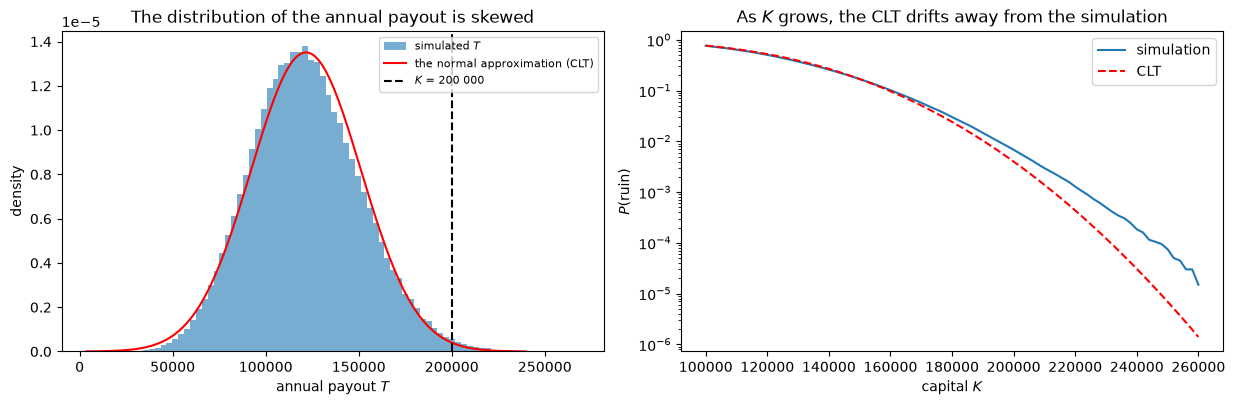

In [7]:
sc = SCENARIO_A
M_ = 200_000
T_samples = sorted(annual_payout(sc["N"], sc["p"], sc["L"]) for _ in range(M_))


def p_ruin_from_quantile(K):
    '''P(T > K) from the sorted array of simulated payouts.'''
    return (M_ - bisect_right(T_samples, K)) / M_


print("the capital needed, by target probability of ruin:")
for target in (0.05, 0.01, 0.001):
    K_target = T_samples[int((1 - target) * M_)]
    print(f"  ruin at most {target:5.1%}: K = {spaces(K_target, ',.0f')}")

ET, VarT, _ = theory(**sc)
sigma = math.sqrt(VarT)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.hist(T_samples, bins=80, density=True, alpha=0.6, label="simulated $T$")
grid = [ET + sigma * (i / 50 - 4) for i in range(401)]
ax.plot(grid, [math.exp(-((x - ET) / sigma) ** 2 / 2) / (sigma * math.sqrt(2 * math.pi)) for x in grid],
        "r", label="the normal approximation (CLT)")
ax.axvline(sc["K"], color="black", linestyle="--", label=f"$K$ = {spaces(sc['K'])}")
ax.set_xlabel("annual payout $T$")
ax.set_ylabel("density")
ax.set_title("The distribution of the annual payout is skewed")
ax.legend(fontsize=8)

ax = axes[1]
Ks = [100_000 + 2_000 * i for i in range(81)]
ax.semilogy(Ks, [p if (p := p_ruin_from_quantile(K)) > 0 else None for K in Ks], label="simulation")
ax.semilogy(Ks, [1 - Phi((K - ET) / sigma) for K in Ks], "r--", label="CLT")
ax.set_xlabel("capital $K$")
ax.set_ylabel("$P(\\mathrm{ruin})$")
ax.set_title("As $K$ grows, the CLT drifts away from the simulation")
ax.legend()
plt.tight_layout()
plt.show()

The right-hand plot has a logarithmic axis and shows the heart of the problem: the further into the
tail, the more the normal approximation drifts away from the simulation — and always on the dangerous
side, i.e. it **understates** the risk. And yet it is precisely the tail (rare large claims) that the
insurance company cares about most.

Notice also where the simulated curve ends: below roughly $10^{-5}$ it has nothing left to draw on,
because $200\,000$ samples simply do not contain rarer events. If we wanted the capital for
$p_u = 10^{-6}$, we have to reach for the weighting from section 4.

## 6. An alternative: NumPy

The whole model can be written without loops. The number of claims in a year is
$\operatorname{Binomial}(N, p)$, the sizes of all the claims are generated at once, and `bincount`
adds them up per year.

In [8]:
try:
    import numpy as np

    rng = np.random.default_rng(1)

    def annual_payout_numpy(sc, M_, p=None):
        '''M annual payouts at once; p can be overridden (for importance sampling).'''
        p = sc["p"] if p is None else p
        counts = rng.binomial(sc["N"], p, size=M_)
        sizes = sc["L"] * np.sqrt(rng.random(counts.sum()))
        T = np.bincount(np.repeat(np.arange(M_), counts), weights=sizes, minlength=M_)
        return T, counts

    sc = SCENARIO_A
    M_ = 2_000_000

    t0 = time.perf_counter()
    T, _ = annual_payout_numpy(sc, M_)
    p_hat = float(np.mean(T > sc["K"]))
    t_np = time.perf_counter() - t0
    lo, hi = interval_wilson(p_hat, M_)
    print(f"plain,    M = {spaces(M_)}: p_u = {p_hat:.5f}, 95% Wilson [{lo:.5f}, {hi:.5f}]   ({t_np:.2f} s)")

    # importance sampling, vectorized
    K_target = 300_000
    q = K_target / (sc["N"] * 2 * sc["L"] / 3)
    t0 = time.perf_counter()
    T, counts = annual_payout_numpy(sc, M_, p=q)
    log_w = counts * np.log(sc["p"] / q) + (sc["N"] - counts) * np.log((1 - sc["p"]) / (1 - q))
    w = np.where(T > K_target, np.exp(log_w), 0.0)
    t_np = time.perf_counter() - t0
    print(f"weighted, K = {spaces(K_target)}: p_u = {w.mean():.3e} +- {w.std(ddof=1) / math.sqrt(M_):.1e}   ({t_np:.2f} s)")
    gain = w.mean() * (1 - w.mean()) / w.std(ddof=1) ** 2   # variance of plain MC / variance of the weighting
    print(f"           plain MC would need on the order of {gain:,.0f}x more runs for the same accuracy".replace(",", " "))
except ModuleNotFoundError:
    print("NumPy is not installed, run:  uv sync")

plain,    M = 2 000 000: p_u = 0.00706, 95% Wilson [0.00695, 0.00718]   (0.76 s)


weighted, K = 300 000: p_u = 1.703e-07 +- 1.5e-09   (2.40 s)
           plain MC would need on the order of 37 369x more runs for the same accuracy


## Summary

| Step | Tool | Where from |
|------|------|------------|
| the claim size $R = \sqrt{\gamma}$ | the inverse transform | exercise 4 |
| the gaps between claims | the geometric distribution in one number | exercise 3 |
| the claim times in the year | an ordered sample in $O(k)$ | exercise 5 |
| a confidence interval for $p_u$ | CLT / Chebyshev / **Wilson** | exercises 0 and 2 |
| a rare ruin | importance sampling, $q^\star = K/(N\cdot 2L/3)$ | exercise 7 |
| the capital needed | a quantile from a single set of samples | exercise 5 |

Three things to take away:

1. **The normal approximation understates the tail.** For a skewed $T$ the CLT gives
   $p_u \approx 0.004$ where the truth is $0.007$ — and the further into the tail, the worse it gets.
2. **The CLT interval fails exactly where you need it.** When $\hat p = 0$, it claims $[0,0]$. Wilson
   does not have this trap.
3. **For rare events, plain MC fails silently.** Zero hits looks like an answer. Importance sampling
   returns an estimate even where plain MC has not a single hit.

---

**But the model has one silent assumption.** The whole capital $K$ (the initial capital *plus the
entire year's premiums*) is available on the first of January — which is why it was enough to track
the annual total and the order of the claims did not matter. What happens when the premiums flow in
gradually and the company can be sunk by bad luck in the timing is in the notebook
`applications/insurance_realistic`.

### Try it yourself

1. Try various $q$ in `p_ruin_weighted` (say $0.06$, $q^\star$, $0.2$) and watch the standard error.
   Does it confirm that $q^\star$ is close to the optimum? What happens for too large a $q$?
2. Compute the capital for $p_u = 10^{-6}$ by importance sampling. (Look for $K$ by bisection,
   estimating $p_u$ for each $K$.)
3. Check the unbiasedness: run the weighting for $K = 200\,000$ twenty times and verify that the
   average of the estimates matches the reference value to within two standard errors.
4. In scenario B, $p_u \approx 0.5$. Does the weighting help there? Compute the gain and explain the
   result.
5. The model assumes at most one claim per interval. Replace the number of claims in the year directly
   by a Poisson distribution (exercise 3) and compare $p_u$. How large is the error from the
   discretization?